In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

OpenCV version: 5.0.0
NumPy version: 2.4.6


# Program 1- Read and Dislay Image 

In [70]:
img = cv2.imread("input.jpg")
if img is None:
    print("Image not found")
else:
    print("Image loaded successfully")
    print("Image shape:", img.shape)

Image loaded successfully
Image shape: (529, 378, 3)


In [71]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\NISHAT\Desktop\Computer_Vision_Assignment_1
['.ipynb_checkpoints', 'bilateral_output.jpg', 'Computer_Vision_Assignment_1.ipynb', 'contrast_output.jpg', 'gamma_output.jpg', 'gaussian_output.jpg', 'input.jpg', 'log_output.jpg', 'mean_output.jpg', 'median_output.jpg', 'negative_input.jpg', 'negative_output.jpg', 'noisy_output.jpg', 'restored_output.jpg']


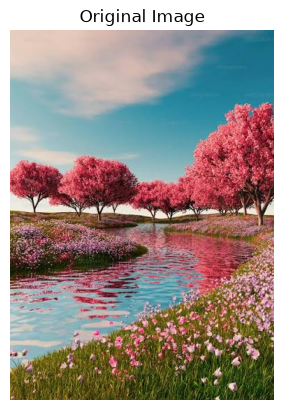

In [72]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

# Program 2- Image Negative

In [12]:
img2 = cv2.imread("negative_input.jpg")
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
print("Image loaded successfully")

Image loaded successfully


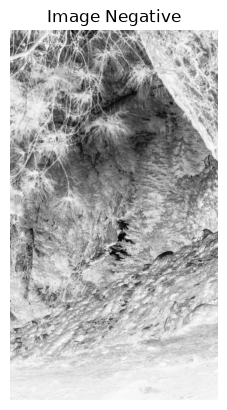

In [13]:
negative = 255 - gray2
plt.imshow(negative, cmap="gray")
plt.title("Image Negative")
plt.axis("off")
plt.show()

In [14]:
cv2.imwrite("negative_output.jpg", negative)
print("Negative image saved successfully")

Negative image saved successfully


# Program 3-Log Transformation

In [78]:
img3 = cv2.imread("input.jpg")
gray3 = cv2.cvtColor(img3, cv2.COLOR_BGR2GRAY)

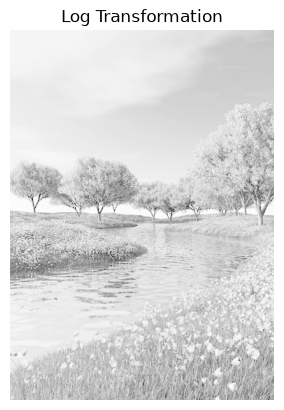

In [79]:
gray_float = gray3.astype(np.float32)
c = 255 / np.log(1 + np.max(gray_float))
log_image = c * np.log(1 + gray_float)
log_image = np.uint8(log_image)
plt.imshow(log_image, cmap="gray")
plt.title("Log Transformation")
plt.axis("off")
plt.show()

In [80]:
cv2.imwrite("log_output.jpg", log_image)
print("Log transformation image saved successfully")

Log transformation image saved successfully


# Program 4- Gamma Transformation

In [81]:
img4 = cv2.imread("input.jpg")
gray4 = cv2.cvtColor(img4, cv2.COLOR_BGR2GRAY)

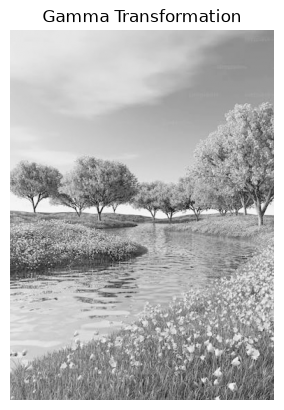

In [82]:
gamma = 0.5
gamma_image = np.power(gray4 / 255.0, gamma)
gamma_image = np.uint8(gamma_image * 255)
plt.imshow(gamma_image, cmap="gray")
plt.title("Gamma Transformation")
plt.axis("off")
plt.show()

In [83]:
cv2.imwrite("gamma_output.jpg", gamma_image)
print("Gamma transformation image saved successfully")

Gamma transformation image saved successfully


# Program 5 — Contrast Stretching

In [85]:
img5 = cv2.imread("input.jpg")
gray5 = cv2.cvtColor(img5, cv2.COLOR_BGR2GRAY)
print("Image loaded successfully")

Image loaded successfully


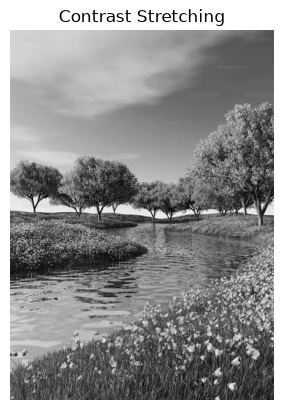

In [86]:
min_val = np.min(gray5)
max_val = np.max(gray5)
contrast = ((gray5 - min_val) / (max_val - min_val)) * 255
contrast = np.uint8(contrast)
plt.imshow(contrast, cmap="gray")
plt.title("Contrast Stretching")
plt.axis("off")
plt.show()

In [25]:
cv2.imwrite("contrast_output.jpg", contrast)
print("Contrast stretching image saved successfully")

Contrast stretching image saved successfully


# Program 6 — Mean/Average Filter

img6 = cv2.imread("input.jpg")
gray6 = cv2.cvtColor(img6, cv2.COLOR_BGR2GRAY)
print("Image loaded successfully")

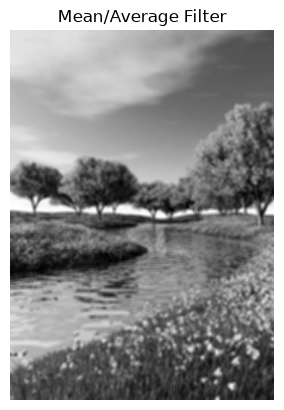

In [87]:
mean_filter = cv2.blur(gray6, (5, 5))
plt.imshow(mean_filter, cmap="gray")
plt.title("Mean/Average Filter")
plt.axis("off")
plt.show()

In [28]:
cv2.imwrite("mean_output.jpg", mean_filter)
print("Mean filter image saved successfully")

Mean filter image saved successfully


# Program 7-Gaussian Filter

In [88]:
img7 = cv2.imread("input.jpg")
gray7 = cv2.cvtColor(img7, cv2.COLOR_BGR2GRAY)
print("Image loaded successfully")

Image loaded successfully


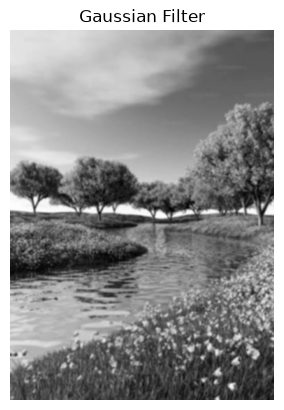

In [89]:
gaussian = cv2.GaussianBlur(gray7, (5, 5), 0)
plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")
plt.show()

In [90]:
cv2.imwrite("gaussian_output.jpg", gaussian)
print("Gaussian filter image saved successfully")

Gaussian filter image saved successfully


# Program 8-Median Filter

In [91]:
img8 = cv2.imread("input.jpg")
gray8 = cv2.cvtColor(img8, cv2.COLOR_BGR2GRAY)
print("Image loaded successfully")

Image loaded successfully


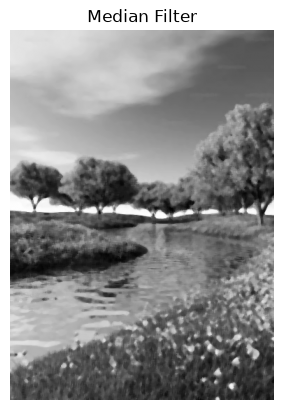

In [92]:
median = cv2.medianBlur(gray8, 5)
plt.imshow(median, cmap="gray")
plt.title("Median Filter")
plt.axis("off")
plt.show()

In [34]:
cv2.imwrite("median_output.jpg", median)
print("Median filter image saved successfully")

Median filter image saved successfully


# Program 9 — Bilateral Filter

In [94]:
img9 = cv2.imread("input.jpg")
gray9 = cv2.cvtColor(img9, cv2.COLOR_BGR2GRAY)
print("Image loaded successfully")

Image loaded successfully


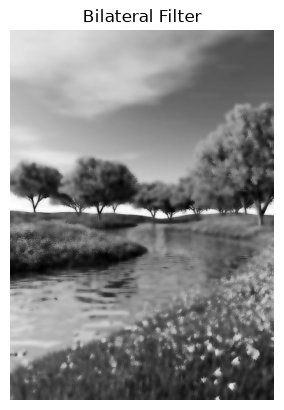

In [93]:
bilateral = cv2.bilateralFilter(gray9, 9, 75, 75)
plt.imshow(bilateral, cmap="gray")
plt.title("Bilateral Filter")
plt.axis("off")
plt.show()

In [37]:
cv2.imwrite("bilateral_output.jpg", bilateral)
print("Bilateral filter image saved successfully")

Bilateral filter image saved successfully


# Program 10 — Image Restoration

In [95]:
img10 = cv2.imread("input.jpg")
gray10 = cv2.cvtColor(img10, cv2.COLOR_BGR2GRAY)
print("Image loaded successfully")

Image loaded successfully


In [96]:
noisy = gray10.copy()
amount = 0.05
num_pixels = int(amount * gray10.size)
# Add salt noise
coords = [np.random.randint(0, i, num_pixels) for i in gray10.shape]
noisy[coords[0], coords[1]] = 255
# Add pepper noise
coords = [np.random.randint(0, i, num_pixels) for i in gray10.shape]
noisy[coords[0], coords[1]] = 0
print("Salt-and-pepper noise added successfully")

Salt-and-pepper noise added successfully


In [97]:
restored = cv2.medianBlur(noisy, 5)
print("Image restored using median filter")

Image restored using median filter


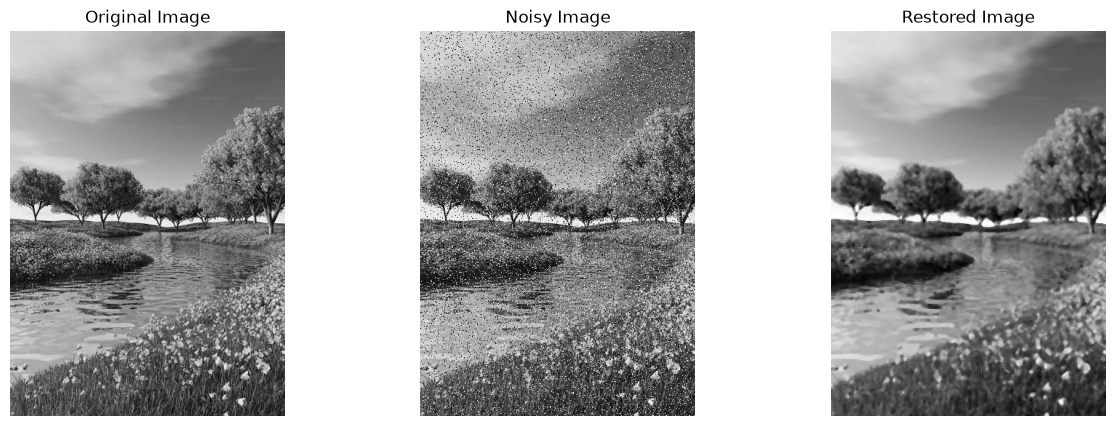

In [98]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(gray10, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(noisy, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(restored, cmap="gray")
plt.title("Restored Image")
plt.axis("off")
plt.show()

In [42]:
cv2.imwrite("noisy_output.jpg", noisy)
cv2.imwrite("restored_output.jpg", restored)
print("Restoration results saved successfully")

Restoration results saved successfully
